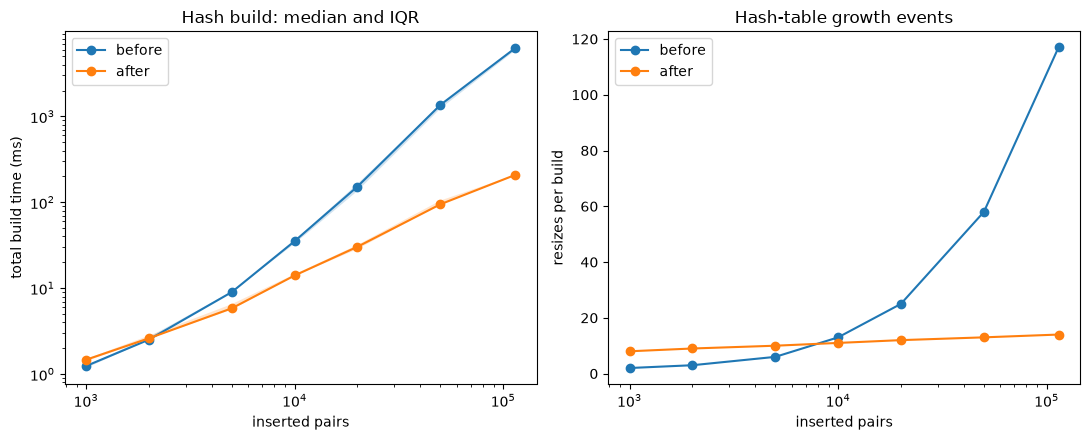

median_ms    q25_ms    q75_ms  resizes  memory_bytes  \
phase  n_keys                                                         
after  1000        1.470     1.406     1.500      8.0      279504.0   
       2000        2.610     2.581     2.800      9.0      554192.0   
       5000        5.839     5.641     6.527     10.0     1197552.0   
       10000      14.060    13.906    14.552     11.0     2432976.0   
       20000      30.361    28.536    31.825     12.0     4900464.0   
       50000      94.858    94.236   104.781     13.0    10845112.0   
       114000    208.138   203.479   208.415     14.0    22264248.0   
before 1000        1.243     1.177     1.247      2.0      278768.0   
       2000        2.517     2.506     2.696      3.0      486000.0   
       5000        9.020     9.004     9.183      6.0     1060784.0   
       10000      35.332    32.997    35.756     13.0     2221624.0   
       20000     152.391   135.256   164.077     25.0     4407920.0   
       50000    1363.242  1232.956  1365.024     58.0    10406776.0   
       114000   6217.307  5847.464  6366.854    117.0    21447768.0   

              code_version    session_id  
phase  n_keys                             
after  1000        584f39d  52cd11d6d84d  
       2000        584f39d  52cd11d6d84d  
       5000        584f39d  52cd11d6d84d  
       10000       584f39d  52cd11d6d84d  
       20000       584f39d  52cd11d6d84d  
       50000       584f39d  52cd11d6d84d  
       114000      584f39d  52cd11d6d84d  
before 1000        fa70927  39da8fbcc1b3  
       2000        fa70927  39da8fbcc1b3  
       5000        fa70927  39da8fbcc1b3  
       10000       fa70927  39da8fbcc1b3  
       20000       fa70927  39da8fbcc1b3  
       50000       fa70927  39da8fbcc1b3  
       114000      fa70927  39da8fbcc1b3

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path("..") if (Path("..") / "results/timings.csv").exists() else Path(".")
df = pd.read_csv(root / "results/timings.csv")

sessions = {
    "before": ("fa70927", "39da8fbcc1b3"),
    "after": ("584f39d", "52cd11d6d84d"),
}

parts = []

for phase, (version, session) in sessions.items():
    part = df[
        (df["experiment"] == "E1_build_memory")
        & (df["index_type"] == "hash_table")
        & (df["machine_id"] == "oscar-omen")
        & (df["code_version"] == version)
        & (df["session_id"] == session)
        & (df["operation"] == "build")
    ].copy()

    assert len(part) == 35, f"{phase}: expected 35 hash-build rows"
    assert set(part["n_keys"]) == {
        1000, 2000, 5000, 10000, 20000, 50000, 114000
    }
    assert part.groupby("n_keys")["rep"].nunique().eq(5).all()
    assert not part.duplicated(["n_keys", "rep"]).any()

    part["phase"] = phase
    part["build_ms"] = part["total_ns"] / 1_000_000
    parts.append(part)

data = pd.concat(parts, ignore_index=True)

summary = data.groupby(["phase", "n_keys"]).agg(
    median_ms=("build_ms", "median"),
    q25_ms=("build_ms", lambda x: x.quantile(.25)),
    q75_ms=("build_ms", lambda x: x.quantile(.75)),
    resizes=("resizes", "median"),
    memory_bytes=("memory_bytes", "median"),
    code_version=("code_version", "first"),
    session_id=("session_id", "first"),
)

figures = root / "report/figures/incidents"
tables = root / "report/tables/incidents"
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

summary.to_csv(tables / "INC-03_hash_build_before_after.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for phase in ["before", "after"]:
    s = summary.loc[phase].sort_index()

    axes[0].plot(s.index, s["median_ms"], marker="o", label=phase)
    axes[0].fill_between(
        s.index, s["q25_ms"], s["q75_ms"], alpha=.2
    )

    axes[1].plot(s.index, s["resizes"], marker="o", label=phase)

axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="inserted pairs",
    ylabel="total build time (ms)",
    title="Hash build: median and IQR",
)

axes[1].set(
    xscale="log",
    xlabel="inserted pairs",
    ylabel="resizes per build",
    title="Hash-table growth events",
)

for ax in axes:
    ax.legend()

fig.tight_layout()
fig.savefig(
    figures / "INC-03_hash_build_before_after.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

summary.round(3)